## Caso de Negocio: Beta Bank Proyecto de predicción de abandono bancario

# Objetivo
El presente trabajo se realizó para identificar el modelo óptimo que permita a Beta Bank identificar clientes con posibilidad de cancelar su cuenta en la institución y permita al banco tomar medidas para disminuir el abandono de manera significativa.

## 1. Preparación de la información.

In [201]:
# iniciamos direccionando el df para acceder a información y bajando las herramientas necesarias para su exploración y análisis
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils import shuffle
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils import resample
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline
# Instalar la biblioteca necesaria para aplicar técnicas de balanceo
%pip install imbalanced-learn


# Cargar los datos desde la carpeta del proyecto
data = pd.read_csv("Churn.csv")  # Inicio del proceso de análisis con el llamado de las herramientas necesarias.

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [202]:
print('Información básica del DataFrame:') # Revisión de la base de datos de origen.
print()
print(data.info())
print()
print('Tipo de variables:') # identificar el tipo de variables, numéricas y categóricas 
print()
print(data.dtypes)
print()
print(data.head()) # Revisión de como se presenta la información

Información básica del DataFrame:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB
None

Tipo de variables:

RowNumber            int64
Custom

## 2. Análisis exploratorio de los datos.  

In [203]:
# Revisamos la integridad de los datos:
print('Revisión de posibles datos duplicados o datos faltanes:')
print()
print('Datos duplicados:')
print(data.duplicated().sum()) # como parte del proceso de limpieza de la data
print()
print('Datos faltantes:') # continuando con el proceso de limpieza
print(data.isna().sum())


Revisión de posibles datos duplicados o datos faltanes:

Datos duplicados:
0

Datos faltantes:
RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64


In [204]:
print('Zoom de valores ausentes:')
missing_tenure= data[data['Tenure'].isna()] # revisión de los datos faltantes para determinar como manipularlos
print(missing_tenure)

Zoom de valores ausentes:
      RowNumber  CustomerId    Surname  CreditScore Geography  Gender  Age  \
30           31    15589475    Azikiwe          591     Spain  Female   39   
48           49    15766205        Yin          550   Germany    Male   38   
51           52    15768193  Trevisani          585   Germany    Male   36   
53           54    15702298   Parkhill          655   Germany    Male   41   
60           61    15651280     Hunter          742   Germany    Male   35   
...         ...         ...        ...          ...       ...     ...  ...   
9944       9945    15703923    Cameron          744   Germany    Male   41   
9956       9957    15707861      Nucci          520    France  Female   46   
9964       9965    15642785    Douglas          479    France    Male   34   
9985       9986    15586914     Nepean          659    France    Male   36   
9999      10000    15628319     Walker          792    France  Female   28   

      Tenure    Balance  NumOfProduct

Al revisar la información del DF encuentro que las variables son numéricas y categóricas, existen 909 datos ausentes de la columna 'Tenure' que representa el periodo de maduración de las inversiones a plazo y que considero a aquellos datos ausentes como: clientes que no tienen este tipo de producto financiero con la institución por lo que asignaré el valor 0 en tales casos.
Limitación: esta sustitución considera los valores ausentes como si representaran una antigüedad de cero años, lo que no necesariamente refleja la situación real de los clientes. Por ello, debe tenerse en cuenta al interpretar los resultados del modelo.

In [205]:
print('Estadística de variables numéricas:')
print(data.describe(include='all')) # se identifican las escalas de las diferentes variables numéricas
print()
print('Estadísticas de variables categóricas:')
print(data[['Surname', 'Geography', 'Gender']].describe(include = 'object')) #Revisamos las variables categóricas
data['Tenure']=data['Tenure'].fillna(0) # los valores ausentes de 'Tenure' son modificados al valor 0
print()
print('Información del DF depurada:')
print()
print(data.info()) # Confirmo que ya no tenemos valores ausentes
print(data.shape)
print()
print('Columnas de alta cardinalidad:')
for col in data.select_dtypes(include='object'): #revisamos las columnas para evitar las de alta cardinalidad
    print(col, ':', data[col].nunique())


Estadística de variables numéricas:
          RowNumber    CustomerId Surname   CreditScore Geography Gender  \
count   10000.00000  1.000000e+04   10000  10000.000000     10000  10000   
unique          NaN           NaN    2932           NaN         3      2   
top             NaN           NaN   Smith           NaN    France   Male   
freq            NaN           NaN      32           NaN      5014   5457   
mean     5000.50000  1.569094e+07     NaN    650.528800       NaN    NaN   
std      2886.89568  7.193619e+04     NaN     96.653299       NaN    NaN   
min         1.00000  1.556570e+07     NaN    350.000000       NaN    NaN   
25%      2500.75000  1.562853e+07     NaN    584.000000       NaN    NaN   
50%      5000.50000  1.569074e+07     NaN    652.000000       NaN    NaN   
75%      7500.25000  1.575323e+07     NaN    718.000000       NaN    NaN   
max     10000.00000  1.581569e+07     NaN    850.000000       NaN    NaN   

                 Age       Tenure        Balance  N

## 3. División de datos en validación, entrenamiento y prueba.

In [206]:
# 1. Definir características y variable objetivo
data_model = data.drop(
    columns=['RowNumber', 'CustomerId', 'Surname']
).copy()

X = data_model.drop(columns='Exited')
y = data_model['Exited']

# 2. Separar entrenamiento, validación y prueba
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12345,
    stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=12345,
    stratify=y_temp
)

# 3. Comprobar dimensiones y valores ausentes
print("Entrenamiento:", X_train.shape)
print("Validación:", X_valid.shape)
print("Prueba:", X_test.shape)

print("\nValores ausentes en entrenamiento:")
print(X_train.isna().sum())

Entrenamiento: (6000, 10)
Validación: (2000, 10)
Prueba: (2000, 10)

Valores ausentes en entrenamiento:
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
dtype: int64


Decisión de eliminar las columnas 'RowNumber', 'Customer Id' y 'Surname' debido a su nula aportación de valor, alta cardinalidad y posible ruido en la elaboración de los modelos de estimación del 'churn'.
Hicimos la división de datos en entrenamiento, validación y prueba para comparar los modelos, ajustar los hiperparámetros y comprobar que el modelo no se limita a memorizar los datos del entrenamiento.

In [207]:
# solo verificación de datos
print("Valores ausentes en data:")
print(data['Tenure'].isna().sum())

print("\nDistribución de Tenure en entrenamiento:")
print(X_train['Tenure'].value_counts(dropna=False).sort_index())

Valores ausentes en data:
0

Distribución de Tenure en entrenamiento:
Tenure
0.0     791
1.0     539
2.0     586
3.0     577
4.0     530
5.0     555
6.0     520
7.0     550
8.0     542
9.0     547
10.0    263
Name: count, dtype: int64


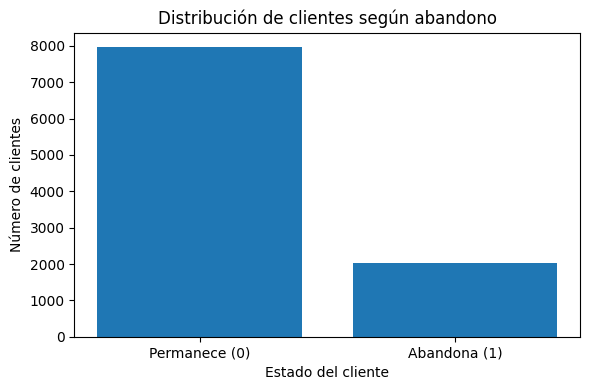

In [208]:
# Gráfica 1: distribución de clientes que permanecen y abandonan el banco

# Contar clientes por clase en el conjunto de datos original
conteo_clases = data['Exited'].value_counts().sort_index()

# Crear la gráfica de barras
plt.figure(figsize=(6, 4))
plt.bar(['Permanece (0)', 'Abandona (1)'], conteo_clases.values)

plt.title('Distribución de clientes según abandono')
plt.xlabel('Estado del cliente')
plt.ylabel('Número de clientes')
plt.tight_layout()
plt.show()

## 4. Preprocesamiento de variables.

In [209]:
# Identificar los tipos de características
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Preprocesamiento de variables numéricas
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocesamiento de variables categóricas
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore'
    ))
])

# Integrar ambos procesos
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)

Variables numéricas: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Variables categóricas: ['Geography', 'Gender']


Generamos un preprocesamiento de variables numéricas y categóricas que podrá aprender sus parámetros exclusivamente de los datos de entrenamiento cuando ajustemos el modelo.

## 5. Entrenamiento y evaluación de modelo inicial.

In [210]:
# Integrar el preprocesamiento y el modelo
model_baseline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(random_state=12345, solver='liblinear', max_iter=1000))])

# Entrenar exclusivamente con el conjunto de entrenamiento
model_baseline.fit(X_train, y_train)

# Evaluar en validación
pred_valid = model_baseline.predict(X_valid)
prob_valid = model_baseline.predict_proba(X_valid)[:, 1]

print(f"F1 en validación: {f1_score(y_valid, pred_valid):.3f}")
print(f"AUC-ROC en validación: {roc_auc_score(y_valid, prob_valid):.3f}")
print(f"Accuracy en validación: {accuracy_score(y_valid, pred_valid):.3f}")

F1 en validación: 0.325
AUC-ROC en validación: 0.787
Accuracy en validación: 0.819


Creamos el modelo de referencia para comparar con otros modelos y poder mejorar las métricas y por lo tanto el valor que aporta el modelo.

In [211]:
print("Distribución de clases en entrenamiento:")
print(y_train.value_counts())

print("\nPorcentaje de cada clase:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Distribución de clases en entrenamiento:
Exited
0    4777
1    1223
Name: count, dtype: int64

Porcentaje de cada clase:
Exited
0    79.62
1    20.38
Name: proportion, dtype: float64


Encontramos un desequilibrio importante en clases, 80% de los clientes permanecen y el 20% lo abandonan, esto ayuda a explicar por qué F1 es de solo 0.325 sin considerarlo como la única causa.

In [212]:
model_balanced = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(random_state=12345,solver='liblinear', max_iter=1000, class_weight='balanced'))]) 
model_balanced.fit(X_train, y_train)

pred_valid_balanced = model_balanced.predict(X_valid)
prob_valid_balanced = model_balanced.predict_proba(X_valid)[:, 1]

print(f"F1 en validación: {f1_score(y_valid, pred_valid_balanced):.3f}")
print(f"AUC-ROC en validación: {roc_auc_score(y_valid, prob_valid_balanced):.3f}")
print(f"Accuracy en validación: {accuracy_score(y_valid, pred_valid_balanced):.3f}")

F1 en validación: 0.510
AUC-ROC en validación: 0.792
Accuracy en validación: 0.718


Con este modelo asignamos mayor peso a los errores de la clase minoritaria sin modificar las observaciones del conjunto de entrenamiento.

## 6. Tratamiento de desbalance de clases.

In [213]:
# Importar la herramienta para sobremuestrear la clase minoritaria
from imblearn.over_sampling import RandomOverSampler

# Crear el sobremuestreador y aplicarlo únicamente al conjunto de entrenamiento
oversampler = RandomOverSampler(random_state=12345)
X_train_over, y_train_over = oversampler.fit_resample(X_train, y_train)

# Comprobar la distribución de clases después del sobremuestreo
print("# Distribución de clases después del sobremuestreo:")
print(y_train_over.value_counts())

# Entrenar la regresión logística con los datos sobremuestreados
# El preprocesamiento se ajustará dentro del pipeline con los datos de entrenamiento
model_oversampling = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        random_state=12345,
        solver='liblinear',
        max_iter=1000
    ))
])

model_oversampling.fit(X_train_over, y_train_over)

# Evaluar el modelo con el conjunto de validación original, sin balancearlo
pred_valid_over = model_oversampling.predict(X_valid)
prob_valid_over = model_oversampling.predict_proba(X_valid)[:, 1]

print(f"F1 en validación: {f1_score(y_valid, pred_valid_over):.3f}")
print(f"AUC-ROC en validación: {roc_auc_score(y_valid, prob_valid_over):.3f}")
print(
    f"Accuracy en validación: {accuracy_score(y_valid, pred_valid_over):.3f}")

# Distribución de clases después del sobremuestreo:
Exited
0    4777
1    4777
Name: count, dtype: int64
F1 en validación: 0.512
AUC-ROC en validación: 0.793
Accuracy en validación: 0.720


Integramos al modelo el sobremuestreo para tratar el desequilibrio: Aumentar la representación de la clase minoritaria en el conjunto de entrenamiento con lo que logramos mejorar la métrica de F1.

In [214]:
# Crear el pipeline con preprocesamiento y Random Forest balanceado
model_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=12345,
        n_jobs=-1
    ))
])

# Entrenar el modelo únicamente con el conjunto de entrenamiento original
model_rf.fit(X_train, y_train)

# Predecir la clase y obtener las probabilidades en validación
pred_valid_rf = model_rf.predict(X_valid)
prob_valid_rf = model_rf.predict_proba(X_valid)[:, 1]

# Evaluar el modelo en validación
print(f"F1 en validación: {f1_score(y_valid, pred_valid_rf):.3f}")
print(f"AUC-ROC en validación: {roc_auc_score(y_valid, prob_valid_rf):.3f}")
print(f"Accuracy en validación: {accuracy_score(y_valid, pred_valid_rf):.3f}")

F1 en validación: 0.639
AUC-ROC en validación: 0.866
Accuracy en validación: 0.840


## 7. Comparación y selección del modelo.

In [215]:
# Comparación de los resultados de los modelos en validación

# Reunir las métricas obtenidas por cada modelo
resultados_modelos = pd.DataFrame({'Modelo': ['Regresión logística base', 'Regresión logística balanceada', 'Regresión logística con sobremuestreo', 'Random Forest balanceado'],'F1': [0.325, 0.510, 0.512, 0.639],'AUC-ROC': [0.787, 0.792, 0.793, 0.866], 'Accuracy': [0.819, 0.718, 0.720, 0.840]})
# Ordenar los modelos de menor a mayor F1
resultados_modelos = resultados_modelos.sort_values(by='F1', ascending=False).reset_index(drop=True)
# Mostrar la tabla comparativa
display(resultados_modelos.round(3))

,Modelo,F1,AUC-ROC,Accuracy
0,Random Forest balanceado,0.639,0.866,0.840
1,Regresión logística con sobremuestreo,0.512,0.793,0.720
2,Regresión logística balanceada,0.510,0.792,0.718
3,Regresión logística base,0.325,0.787,0.819


El modelo Random Forest balanceado con un umbral final de 0.51 muestra el mejor desempeño de las métricas clave. El modelo detecta 69 de cada 100 clientes que abandonan, aunque también genera falsas alarmas: aproximadamente 42% de los clientes señalados como desertores no abandonan.
Esto puede ser útil para una estrategia de retención de clientes, pero el banco debe evaluar el costo de contactar a esos clientes frente al beneficio de retener a los que podrían abandonar.

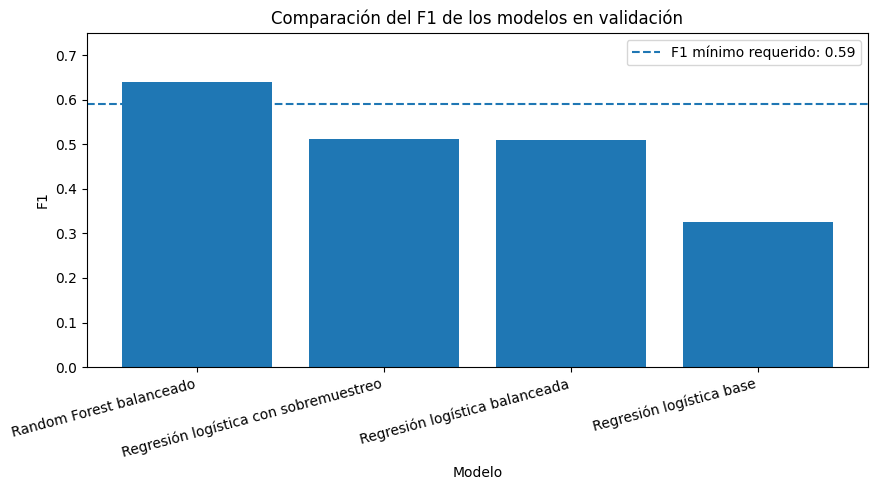

In [216]:
# Gráfica 2: comparación del F1 de los modelos en validación
# Obtener los nombres de los modelos y sus valores F1
modelos = resultados_modelos['Modelo']
f1_scores = resultados_modelos['F1']

# Crear la gráfica de barras
plt.figure(figsize=(9, 5))
plt.bar(modelos, f1_scores)

# Mostrar el F1 mínimo requerido por el proyecto
plt.axhline(
    y=0.59,
    linestyle='--',
    label='F1 mínimo requerido: 0.59'
)

# Configurar la gráfica
plt.title('Comparación del F1 de los modelos en validación')
plt.xlabel('Modelo')
plt.ylabel('F1')
plt.ylim(0, 0.75)
plt.xticks(rotation=15, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

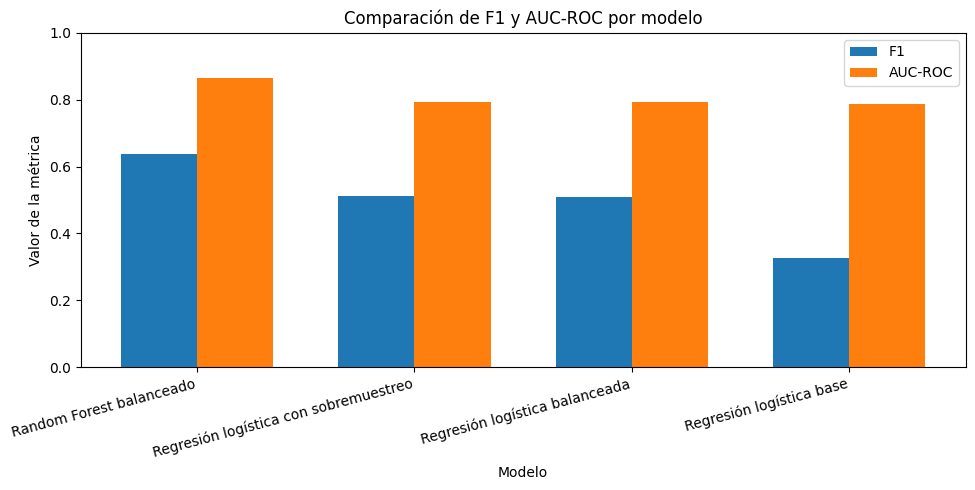

In [217]:
# Obtener los nombres de los modelos y sus métricas
modelos = resultados_modelos['Modelo']
f1_scores = resultados_modelos['F1']
auc_scores = resultados_modelos['AUC-ROC']

# Definir la posición de las barras
posiciones = np.arange(len(modelos))
ancho = 0.35

# Crear las barras para ambas métricas
plt.figure(figsize=(10, 5))
plt.bar(posiciones - ancho / 2, f1_scores, ancho, label='F1')
plt.bar(posiciones + ancho / 2, auc_scores, ancho, label='AUC-ROC')

# Configurar la gráfica
plt.title('Comparación de F1 y AUC-ROC por modelo')
plt.xlabel('Modelo')
plt.ylabel('Valor de la métrica')
plt.xticks(posiciones, modelos, rotation=15, ha='right')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Ajuste del umbral

In [218]:
# Explorar distintos umbrales de clasificación para maximizar el F1

# Calcular las probabilidades de abandono en validación
prob_valid_rf = model_rf.predict_proba(X_valid)[:, 1]

# Probar umbrales entre 0.20 y 0.70
umbrales = np.arange(0.20, 0.71, 0.01)
resultados_f1 = []

for umbral in umbrales:
    # Clasificar como abandono cuando la probabilidad alcanza el umbral
    predicciones = (prob_valid_rf >= umbral).astype(int)

    # Calcular el F1 para este umbral
    f1 = f1_score(y_valid, predicciones)
    resultados_f1.append(f1)

# Identificar el umbral con el F1 más alto
mejor_indice = np.argmax(resultados_f1)
mejor_umbral = umbrales[mejor_indice]
mejor_f1 = resultados_f1[mejor_indice]

print(f"Mejor umbral en validación: {mejor_umbral:.2f}")
print(f"Mejor F1 en validación: {mejor_f1:.3f}")

Mejor umbral en validación: 0.51
Mejor F1 en validación: 0.640


## 9. Evaluación final.


In [219]:
# Evaluación final del modelo Random Forest en el conjunto de prueba

# Obtener las probabilidades de abandono para el conjunto de prueba
prob_test_rf = model_rf.predict_proba(X_test)[:, 1]

# Aplicar el umbral seleccionado usando el conjunto de validación
umbral_final = mejor_umbral
pred_test_rf = (prob_test_rf >= umbral_final).astype(int)

# Calcular las métricas finales
print("Resultados finales en el conjunto de prueba:")
print(f"F1:        {f1_score(y_test, pred_test_rf):.3f}")
print(f"AUC-ROC:   {roc_auc_score(y_test, prob_test_rf):.3f}")
print(f"Accuracy:  {accuracy_score(y_test, pred_test_rf):.3f}")
print(f"Precision: {precision_score(y_test, pred_test_rf):.3f}")
print(f"Recall:    {recall_score(y_test, pred_test_rf):.3f}")

Resultados finales en el conjunto de prueba:
F1:        0.630
AUC-ROC:   0.865
Accuracy:  0.836
Precision: 0.581
Recall:    0.688


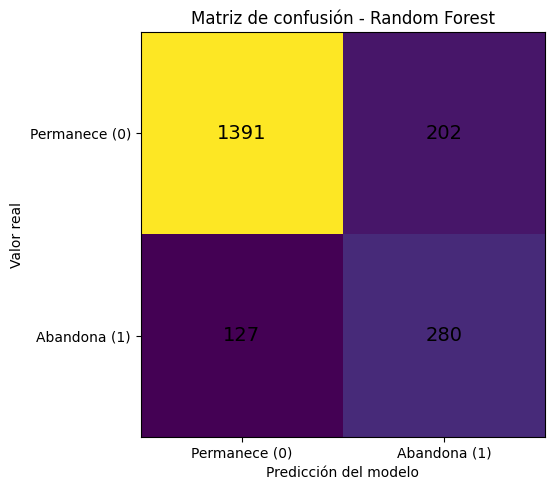

In [220]:
# Gráfica 4: matriz de confusión del modelo final

# Obtener las predicciones del modelo final
probabilidades_test = model_rf.predict_proba(X_test)[:, 1]
pred_test_rf = (probabilidades_test >= mejor_umbral).astype(int)

# Calcular la matriz de confusión
matriz = confusion_matrix(y_test, pred_test_rf)

# Mostrar la matriz como una gráfica
plt.figure(figsize=(6, 5))
plt.imshow(matriz)

# Agregar los valores dentro de cada celda
for fila in range(matriz.shape[0]):
    for columna in range(matriz.shape[1]):
        plt.text(
            columna, fila,
            matriz[fila, columna],
            ha='center',
            va='center',
            fontsize=14
        )

# Configurar los ejes y el título
plt.title('Matriz de confusión - Random Forest')
plt.xlabel('Predicción del modelo')
plt.ylabel('Valor real')
plt.xticks([0, 1], ['Permanece (0)', 'Abandona (1)'])
plt.yticks([0, 1], ['Permanece (0)', 'Abandona (1)'])
plt.tight_layout()
plt.show()

## 10. Conclusiones del proyecto: Predicción del abandono de clientes de Beta Bank

El objetivo del proyecto fue desarrollar un modelo de clasificación capaz de identificar a los clientes con mayor probabilidad de abandonar el banco, alcanzando un valor F1 mínimo de 0.59.

Se identificó un desequilibrio entre las clases: aproximadamente el 79.6% de los clientes permanecía en el banco y el 20.4% había abandonado. Por esta razón, se evaluaron diferentes estrategias para tratar el desequilibrio, además de comparar distintos modelos de clasificación.

Se probaron tres alternativas de regresión logística: el modelo base, el modelo con pesos balanceados y el modelo entrenado mediante sobremuestreo de la clase minoritaria. Posteriormente, se evaluó un modelo Random Forest con pesos balanceados, que obtuvo los mejores resultados.

El modelo seleccionado alcanzó un F1 de 0.639 en validación. Se exploraron distintos umbrales de clasificación y como resultado del proceso de valoración sobresalio un coeficiente de 0.51, que produjo un F1 de 0.640 en validación.

En la evaluación final sobre el conjunto de prueba se obtuvieron los siguientes resultados:

- **F1:** 0.630.
- **AUC-ROC:** 0.865.
- **Accuracy:** 0.836.
- **Precision:** 0.581.
- **Recall:** 0.688.

El modelo cumple el requisito del proyecto de alcanzar un F1 de al menos 0.59. Su recall indica que identifica aproximadamente el 68.8% de los clientes que abandonan, mientras que su precisión refleja que todavía existe una proporción importante de falsas alarmas.

En conclusión, el modelo Random Forest con pesos balanceados ofrece un desempeño satisfactorio para el objetivo académico planteado. Su aplicación práctica requeriría evaluar los costos de las acciones de retención, el beneficio de recuperar clientes y el impacto económico de las predicciones incorrectas.
